In [4]:
import experiments.comparison as comparison_module
import json
import data.data as puzzle_data
import experiments.comparison as comparison_module

with open("data/basic_results.json", "r") as file:
    basic_results = json.load(file)

with open("data/mrv_results.json", "r") as file:
    mrv_results = json.load(file)["mrv"]

puzzles = {
    name.replace("puzzle_", ""): value
    for name, value in vars(puzzle_data).items()
    if name.startswith("puzzle_") and isinstance(value, dict)
}

comparison = comparison_module.create_comparison(
    basic_results,
    mrv_results,
    puzzles
)

## 6. Conclusion
The aim of this project was to investigate how different search strategies affect the computational efficiency of solving Meowdoku puzzles. To achieve this, I implemented and compared two constraint-based algorithms: Basic Backtracking and Backtracking with the Minimum Remaining Values (MRV) heuristic.

### Overall Performance Comparison

To summarise the experimental findings, I compared the total number of recursive calls and backtracks performed by both algorithms across all ten puzzles.

The results show a substantial reduction in search effort when using the Minimum Remaining Values (MRV) heuristic. This comparison highlights the effect of variable selection on the size of the search process.



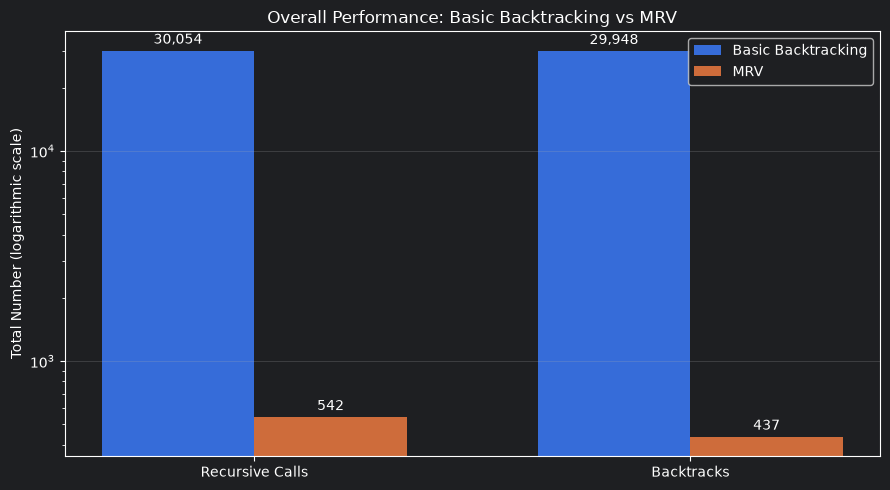

In [5]:
comparison_module.plot_overall_comparison(comparison)


As shown in the chart, basic backtracking performed 30,054 recursive calls and 30,048 backtracks, whereas MRV required only 542 recursive calls and 437 backtracks. These results correspond to reductions of approximately 98.20% and 98.54%, respectively.

This demonstrates that selecting the most constrained region first substantially reduces the amount of search required for the tested puzzles. However, as discussed in Part 3, this reduction in search effort does not necessarily result in shorter execution time because MRV introduces additional computational overhead.

Overall, this project demonstrates how mathematical concepts such as constraint satisfaction, combinatorics, and algorithmic search can be applied to a practical problem. It also highlights the importance of evaluating algorithms using multiple performance indicators rather than relying exclusively on execution time.

## 7. Limitations and Future Work

Although the experiments provided useful insights into the performance of the two algorithms, several limitations should be considered.

First, the dataset contains only ten Meowdoku puzzles. Although these puzzles provide a basis for comparing the algorithms, a larger and more diverse dataset would be necessary to establish whether the observed results apply more generally. Initially my goal was to gather as many puzzles as possible, however transcribing each puzzle into a matrix proved to be very time-consuming.

Second, execution times depend not only on the algorithms but also on the hardware, operating system, background processes, and Python environment. Repeating each experiment five times and using the median reduced the influence of timing fluctuations, but it could not eliminate them completely.

Third, the comparison involved only two search strategies: Basic Backtracking and MRV. Other approaches, such as forward checking or more advanced constraint-propagation techniques, were outside the scope of this project.

Future work could address these limitations by testing a larger collection of puzzles with different difficulty levels, repeating benchmarks across different computational environments, and implementing additional constraint-solving strategies. It would also be useful to investigate how puzzle structure and the number of legal candidate cells influence the performance of each algorithm.

These improvements could provide a broader understanding of constraint-based search and help identify which strategies are most effective for different types of Meowdoku puzzles.

## 8. References

The following sources provide the theoretical and technical foundations for this project.

Mackworth, A. K. (1977). Consistency in Networks of Relations. Artificial Intelligence, 8(1), 99–118.

Russell, S. J., & Norvig, P. (2021). Artificial Intelligence: A Modern Approach (4th ed.). Pearson.

Python Software Foundation. Python 3 Documentation: time — Time access and conversions. https://docs.python.org/3/library/time.html

Oakever Games. (n.d.). *Meowdoku: Brain Puzzle Games* [Mobile app]. Google Play. https://play.google.com/store/apps/details?id=com.oakever.meowdoku